In [2]:
import numpy as np 
import matplotlib.pyplot as plt 

# Zadanie 1. 
    $ tg(\pi - x) - x = 0 $

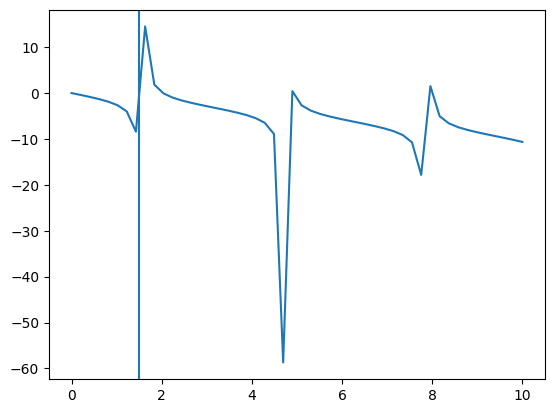

In [3]:
# szybka diagnostyka
a = np.linspace(0, 10)

y = np.tan(np.pi - a) -a 

plt.plot(a,y)
plt.axvline(1.5)


metoda bisekcji

In [4]:
def func(x):
    return np.tan(np.pi - x) - x 

# mądrze wybieramy przedział
start =1.7
end = 3.1
epsilon = 1e-7

def bisection(start, end, func, tolerance):
    """Znajduje miejsce zerowe dla przedziału [start,end]

    Args:
        start (float): poczatek przedziału
        end (float): koniec przedziału
        func (function): funkcja której miejsca zerowego szukamy
        tolerance (float): szerokosc przedziału po ktorym przestajemy szukac lepszego przyblizenia
        counting_ierations (bool, optional): liczba iteracji petli ktorej uzywam do kolejnego zadania. Defaults to False.

    Returns:
        m: miejsce zerowe
        opcjonalnie: m, ilosc iteracji
    """    
    iteration_count = 0
    if func(start) * func(end) > 0:
        print("funkcja nie zmienia znaku")
    else:
        while np.abs(end - start) > tolerance and iteration_count < 9999:
            iteration_count+=1
            m = (start + end) /2
            if func(m) == 0:
                break
            if func(start) * func(m) < 0:
                end = m 
            else:
                start=m
        m = (start + end)/2
        print("found solution in", iteration_count, "iterations")
        return m 
    
iterations_bis = bisection(start, end, func, epsilon)
print(iterations_bis)
print()


found solution in 24 iterations
2.0287578165531155



metoda brenta

In [5]:

def brent_method(start, end, func, tolerance, maxit=2000):
    iteration_count = 0
    fs =func(start)
    fe = func(end)
    if func(start) * func(end) > 0:
        print("funkcja nie zmienia znaku")
        return None
    else:
        while np.abs(end-start) > tolerance and iteration_count < maxit:
            iteration_count+=1
            m = (start + end)/2
            fm = func(m)

            if np.abs(fm) < tolerance or fm == 0: 
                start, end = m, m 
                break
            denom = (fs - fe) * (fe - fm) * (fm - fs) 

            if np.abs(denom) > 1e-15: 
                x = (start *fe* fm * (fe - fm) + end * fm * fs * (fm -fs) + m * fs * fe * (fs - fe)) / denom
            else:
                x = m

            if start < x < end:
                fx = func(x)
                if fx == 0 or np.abs(fx) < tolerance:   
                    print("found solution in", iteration_count, "iterations.")  
                    return x
                if fs * fx < 0:
                    end, fe = x, fx
                else:
                    start, fs = x, fx
            else:
                if fs * fm < 0:
                    end, fe = m, fm
                else:
                    start, fs = m, fm

        root = (start + end)/2
        print("found solution in", iteration_count, "iterations.")
        return root
        
    


iterations_brent = brent_method(start, end, func, epsilon) 
print(iterations_brent)



        
    


found solution in 24 iterations.
2.0287578165531155


metoda siecznych 

In [6]:
# reguła Falsi z wykładu
def regula(func, a, b, delta, epsilon, maxit):
    fa = func(a); fb = func(b)
    if fa * fb > 0: 
        raise ValueError("Wrong interval!")
    for k in range(maxit):
        dx = fb*(b-a)/(fb-fa)
        x = b-dx
        ac = x-a
        fx = func(x)
        if fx == 0: 
            break
        elif fb * fx > 0:
            b = x; fb = fx
        else:
            a = x; fa = fx

        dx = min(abs(dx), abs(ac))
        if abs(dx) < delta: 
            break
        if abs(fx) < epsilon:
            break
    err = abs(b- a) / 2
    return x, err, fx
print(regula(func,start, end, 10e-6,10e-6, 2000))


def secant_method(func, a, b, epsilon, maxit):
    fa = func(a)
    fb = func(b)

    if fa * fb > 0: 
        raise ValueError("Wrong interval!")
    
    for i in range(maxit):
        if fb == fa:
            print("division by zero")
            break
        dx = fb*(b-a)/(fb-fa)
        x = b-dx
        if abs(dx) < epsilon:
            print("found solution in", i, "iterations.")
            return x
        
        a, b = b, x 
        fa, fb = fb, func(x)
        
    return x

print(secant_method(func, start, end, epsilon, 2000))

(np.float64(2.0287748035597333), np.float64(0.16438740177986666), np.float64(-0.0001037552978311318))
found solution in 11 iterations.
2.0287578381104345


In [7]:
# zawsze trzeba podać pochodną funkcji func
def derivative_func(x):
    return -1 / np.power(np.cos(np.pi - x), 2) - 1

def newton_method(func, Dfunc,b, epsilon, maxit=2000):
    """Znajduje miejsce zerowe znajdujące się obok b, wykorzystując styczne. Wyznacza kolejne przybliżenia x0. 

    Args:
        func (function): funkcja której szukamy miejsc zerowych
        Dfunc (_type_): pochodna func
        b (float): punkt startowy
        epsilon (float): błąd jaki popełniamy
        maxit (int, optional): Zabezpieczenie przed nieskończonymi pętlami. Defaults to 2000.

    Returns:
        float: miejsce zerowe
    """    """"""
    xn = b
    for i in range(maxit):
        fxn = func(xn)
        if abs(fxn) < epsilon:
            print("found solution after", i, "iterations")
            return xn
        Dfxn = Dfunc(xn)
        if Dfxn == 0:
            print("Zero derivative. No solution found.")
            return None
        xn = xn - fxn/Dfxn
    print("exceeded maximum iterations. No solutions found")
    return None

print(newton_method(func, derivative_func, end, epsilon))
print(func(2.0287578381104066))

found solution after 14 iterations
2.0287578381104066
1.687538997430238e-13


Wypełnienie tabelki

In [8]:
start =1.7
end = 3.1
epsilon = 1e-7
print("metoda bisekcji: ",bisection(start, end, func, epsilon))
print("metoda brenta:", brent_method(start, end, func, epsilon))
print("metoda siecznych: ",secant_method(func, start, end, epsilon, 2000) )
print("metoda newtona: ",newton_method(func, derivative_func, end, epsilon))

found solution in 24 iterations
metoda bisekcji:  2.0287578165531155
found solution in 24 iterations.
metoda brenta: 2.0287578165531155
found solution in 11 iterations.
metoda siecznych:  2.0287578381104345
found solution after 14 iterations
metoda newtona:  2.0287578381104066


| | bisekcja | m. Brenta | m. siecznych | m. Newtona |
| :--- | :---: | :---: | :---: | :---: |
| $x$ |$2.0287578165531155$ |$2.0287578165531155$|$2.0287578381104345$|$2.0287578381104066$|
| $f(x)$ |$\tg(\pi - x) - x$ |$\tg(\pi - x) - x$ |$\tg(\pi - x) - x$ |$\tg(\pi - x) - x$ |
| liczba iteracji |24 | 24|11 |14 |
| liczba mnożeń i dodawań |$3 \cdot 24$ |$14 \cdot 24$ |$4 \cdot 11$ |$2 \cdot 14$ |

## Zadanie 2. 

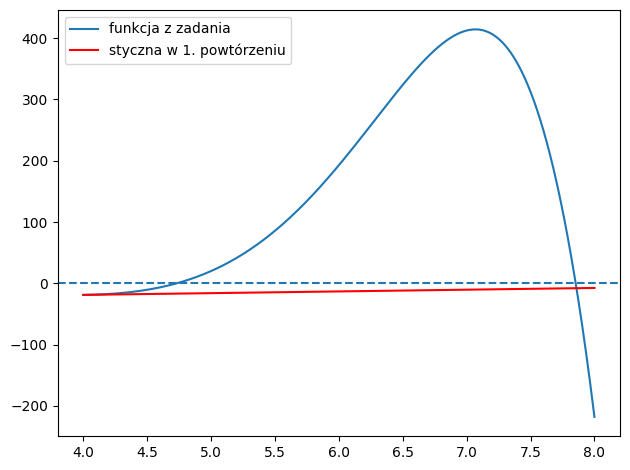

In [9]:
def func_ex2(x):
    return np.cosh(x)*np.cos(x) - 1
def derivative_ex2(x):
    return np.cos(x)*np.sinh(x) - np.cosh(x)*np.sin(x)
x_arg = np.linspace(4,8,1000)

plt.plot(x_arg, func_ex2(x_arg), label ="funkcja z zadania")
plt.plot(x_arg, derivative_ex2(4)* (x_arg - 4) + func_ex2(4), color="red", label="styczna w 1. powtórzeniu")
plt.legend()
plt.tight_layout()
plt.axhline(0, ls="--")

In [10]:
x_out = newton_method(func_ex2, derivative_ex2,4, epsilon)

print(f"funkcja znajduje inne miejsce zerowe w punkcie {x_out} \n" 
f"wartość funkcji w {x_out} wynosi {func_ex2(10.995607838002249)}.")

found solution after 6 iterations
funkcja znajduje inne miejsce zerowe w punkcie 10.995607838002249 
wartość funkcji w 10.995607838002249 wynosi 1.7219616621488854e-08.


found solution in 40 iterations
rakieta osiąga predkość 335 w czasie 70.87797226808107


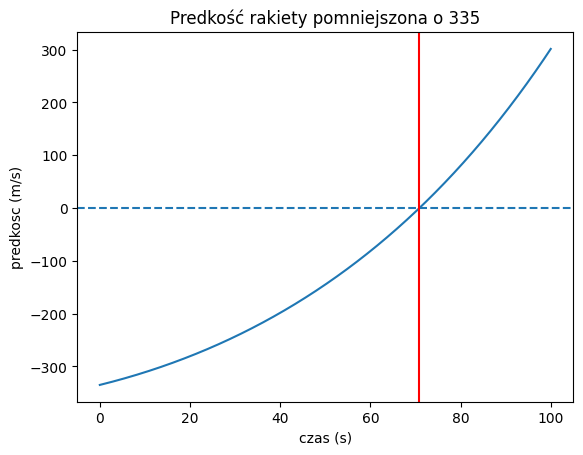

In [12]:
def rocket_velocity(t, desirable_velocity=335):
    u = 2510.0       
    M0 = 2.8e6       
    m_dot = 13.3e3   
    g = 9.81         
    
    return u * np.log(M0 / (M0 - m_dot * t)) - g * t - desirable_velocity
velocity =335
seconds = np.linspace(0,100, 1000)
plt.plot(seconds, rocket_velocity(seconds, desirable_velocity=velocity))
plt.xlabel("czas (s)")
plt.ylabel("predkosc (m/s)")
plt.axhline(0, ls="--")
plt.title(f"Predkość rakiety pomniejszona o {velocity}")

result = bisection(60,80, rocket_velocity, 1e-12)
plt.axvline(result, color="red")
print(f"rakieta osiąga predkość {velocity} w czasie {result}")